# Notebook 9: Strategy Performance Evaluation and Robustness

## Project: Factor Investing and Portfolio Optimization

This notebook evaluates the strategies developed in the earlier notebooks using a consistent set of performance, risk, benchmark-relative, and transaction-cost diagnostics.

**Strategies evaluated**
- Equal-weight portfolio of the selected stocks
- 12–1 momentum portfolio: hold the two stocks with the strongest trailing momentum
- Low-volatility portfolio: hold the two stocks with the lowest trailing volatility
- NIFTY 50 (^NSEI), used as a broad-market reference where data are available

**Important:** this notebook is self-contained and reconstructs the strategy returns so it can be run independently. It uses historical data and simplified trading-cost assumptions. Results are educational research, not investment advice.

## 1. Research questions

1. Which strategy has the strongest return and risk-adjusted performance?
2. How severe and persistent are the strategies' drawdowns?
3. Do the strategies outperform a broad-market reference on a risk-adjusted basis?
4. How sensitive are the results to transaction costs and the evaluation period?
5. Are the conclusions robust enough to justify further research?

### Evaluation principles

- Use the same date window when comparing strategies.
- Form signals using information available at the time and execute targets on the next available trading day.
- Report return and risk metrics together; a high return alone is not sufficient.
- Treat historical results as sample-dependent. A five-stock universe is too small to support broad claims about factor investing.

## 2. Imports and configuration

If a package is missing in Colab, uncomment and run the installation line.

In [13]:
# !pip install yfinance scipy scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import display

TRADING_DAYS = 252
START_DATE = "2020-01-01"
END_DATE = "2026-01-01"  # yfinance end date is exclusive
TICKERS = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS", "ICICIBANK.NS"]
MARKET_TICKER = "^NSEI"
N_HOLDINGS = 2
MOMENTUM_LOOKBACK = 252
MOMENTUM_SKIP = 21
VOLATILITY_WINDOW = 63
ONE_WAY_COST_BPS = 10
RISK_FREE_RATE = 0.0  # annual rate; set a justified rate if desired

print("Configuration loaded.")

Configuration loaded.


## 3. Download and validate adjusted price data

`auto_adjust=True` requests split/dividend-adjusted prices from Yahoo Finance. Downloaded data can change if the data provider revises its history.

In [14]:
raw = yf.download(
    TICKERS + [MARKET_TICKER],
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
    group_by="column",
    threads=True
)

if raw.empty:
    raise RuntimeError("No data were downloaded. Check your internet connection or ticker symbols.")

# yfinance may return either MultiIndex or single-level columns depending on version.
if isinstance(raw.columns, pd.MultiIndex):
    if "Close" in raw.columns.get_level_values(0):
        prices = raw["Close"].copy()
    elif "Close" in raw.columns.get_level_values(-1):
        prices = raw.xs("Close", axis=1, level=-1).copy()
    else:
        raise KeyError("Could not locate Close prices in the downloaded data.")
else:
    prices = raw.copy()

prices = prices.reindex(columns=TICKERS + [MARKET_TICKER])
prices = prices.apply(pd.to_numeric, errors="coerce").sort_index()
prices = prices.dropna(how="all")

stock_prices = prices[TICKERS].dropna(how="all")
stock_prices = stock_prices.ffill(limit=3)
stock_returns = stock_prices.pct_change(fill_method=None)
market_returns = prices[MARKET_TICKER].pct_change(fill_method=None).rename("NIFTY 50")

print(f"Downloaded observations: {len(prices):,}")
print(f"Date range: {prices.index.min().date()} to {prices.index.max().date()}")
print("Missing stock prices after limited forward fill:")
display(stock_prices.isna().sum().to_frame("Missing observations"))
display(stock_prices.tail())

Downloaded observations: 1,487
Date range: 2020-01-01 to 2025-12-31
Missing stock prices after limited forward fill:


,Missing observations
Ticker,
RELIANCE.NS,0
TCS.NS,0
INFY.NS,0
HDFCBANK.NS,0
ICICIBANK.NS,0


Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Date,,,,,
2025-12-24,1551.028687,3181.681885,1628.167480,980.975220,1348.432129
2025-12-26,1552.024048,3144.295654,1621.022095,975.958191,1339.110596
2025-12-29,1538.486694,3116.974365,1609.863525,975.564697,1332.070068
2025-12-30,1532.713379,3112.469482,1587.252808,974.777771,1331.276611
2025-12-31,1563.172607,3073.549072,1581.184204,975.072876,1331.673340


## 4. Construct factor signals and monthly targets

Momentum is measured as the price approximately 12 months ago divided by the price approximately one month ago, minus one. The recent 21 trading days are skipped to reduce short-term reversal effects. Volatility uses a trailing 63-trading-day window. Signals are sampled at month-end and applied on the next available trading day.

In [15]:
# A 12-1 momentum proxy: price[t-21] / price[t-252] - 1
momentum = stock_prices.shift(MOMENTUM_SKIP) / stock_prices.shift(MOMENTUM_LOOKBACK) - 1
rolling_vol = stock_returns.rolling(VOLATILITY_WINDOW, min_periods=VOLATILITY_WINDOW).std() * np.sqrt(TRADING_DAYS)

# Select the actual final observed trading date in each calendar month.
signal_dates = stock_prices.groupby([stock_prices.index.year, stock_prices.index.month]).tail(1).index

# Targets are stored only on execution dates; NaN rows mean "no rebalance today".
monthly_targets = {name: {} for name in ["Equal-weight", "Momentum", "Low-volatility"]}

for signal_date in signal_dates:
    future_dates = stock_prices.index[stock_prices.index > signal_date]
    if len(future_dates) == 0:
        continue
    execution_date = future_dates[0]
    monthly_targets["Equal-weight"][execution_date] = pd.Series(1 / len(TICKERS), index=TICKERS)
    mom_row = momentum.loc[signal_date].dropna()
    vol_row = rolling_vol.loc[signal_date].dropna()
    if len(mom_row) >= N_HOLDINGS:
        chosen = mom_row.nlargest(N_HOLDINGS).index
        monthly_targets["Momentum"][execution_date] = pd.Series(0.0, index=TICKERS)
        monthly_targets["Momentum"][execution_date].loc[chosen] = 1 / len(chosen)
    if len(vol_row) >= N_HOLDINGS:
        chosen = vol_row.nsmallest(N_HOLDINGS).index
        monthly_targets["Low-volatility"][execution_date] = pd.Series(0.0, index=TICKERS)
        monthly_targets["Low-volatility"][execution_date].loc[chosen] = 1 / len(chosen)

targets = {}
for strategy, date_map in monthly_targets.items():
    target = pd.DataFrame(np.nan, index=stock_prices.index, columns=TICKERS)
    for date, weights in date_map.items():
        target.loc[date, :] = weights.reindex(TICKERS).values
    targets[strategy] = target

print("Number of monthly momentum rebalances:", len(monthly_targets["Momentum"]))
print("Number of monthly low-volatility rebalances:", len(monthly_targets["Low-volatility"]))
print("Factor signals are executed on the next available trading day.")

Number of monthly momentum rebalances: 59
Number of monthly low-volatility rebalances: 68
Factor signals are executed on the next available trading day.


## 5. Run the backtest with transaction costs

Turnover is calculated as half the sum of absolute weight changes. Costs are applied on rebalance dates as `turnover × one-way cost`. Portfolio weights drift with realized asset returns between rebalances. This is a simplified daily accounting model; it does not model taxes, bid–ask spread variation, market impact, or liquidity constraints.

In [16]:
def backtest_strategy(asset_returns, target_weights, cost_bps=10):
    """Return daily gross/net returns, turnover and executed weights."""
    idx = asset_returns.index
    cols = asset_returns.columns
    target_weights = target_weights.reindex(index=idx, columns=cols)
    current_weights = pd.Series(0.0, index=cols)
    gross, net, turnover_values, cost_values = [], [], [], []
    executed_weights = []
    cost_rate = cost_bps / 10_000

    for date in idx:
        target = target_weights.loc[date]
        # A row with target values marks a rebalance date; NaN rows mean hold/drift.
        if target.notna().any() and target.fillna(0.0).sum() > 0:
            target = target.fillna(0.0)
            target = target / target.sum()
            turnover = 0.5 * np.abs(target - current_weights).sum()
            current_weights = target.copy()
        else:
            turnover = 0.0

        day_returns = asset_returns.loc[date].fillna(0.0)
        gross_return = float((current_weights * day_returns).sum())
        transaction_cost = float(turnover * cost_rate)
        net_return = gross_return - transaction_cost
        gross.append(gross_return)
        net.append(net_return)
        turnover_values.append(float(turnover))
        cost_values.append(transaction_cost)
        executed_weights.append(current_weights.copy())

        # Drift weights to reflect price changes until the next rebalance.
        denominator = 1 + gross_return
        if denominator > 0:
            current_weights = current_weights * (1 + day_returns) / denominator
            total = current_weights.sum()
            if total > 0:
                current_weights = current_weights / total

    return pd.DataFrame({
        "Gross Return": gross,
        "Net Return": net,
        "Turnover": turnover_values,
        "Transaction Cost": cost_values,
    }, index=idx), pd.DataFrame(executed_weights, index=idx, columns=cols)

results = {}
executed_weights = {}
for name, target in targets.items():
    results[name], executed_weights[name] = backtest_strategy(stock_returns, target, ONE_WAY_COST_BPS)

# Use a common evaluation window beginning when all factor strategies have become invested.
first_valid_dates = [target.index[target.notna().any(axis=1)][0] for target in targets.values() if target.notna().any(axis=1).any()]
common_start = max(first_valid_dates)
common_end = min(results[name].index[results[name]["Net Return"].notna()][-1] for name in results)
strategy_returns = pd.DataFrame({name: frame["Net Return"] for name, frame in results.items()})
strategy_returns = strategy_returns.loc[common_start:common_end].dropna(how="any")
strategy_gross_returns = pd.DataFrame({name: frame["Gross Return"] for name, frame in results.items()}).loc[strategy_returns.index]
market_common = market_returns.reindex(strategy_returns.index)

print("Common strategy evaluation window:", strategy_returns.index.min().date(), "to", strategy_returns.index.max().date())
display(strategy_returns.head())

Common strategy evaluation window: 2021-02-01 to 2025-12-31


,Equal-weight,Momentum,Low-volatility
Date,,,
2021-02-01,0.048383,0.012817,0.035014
2021-02-02,0.024993,0.014287,0.039047
2021-02-03,0.005940,0.004730,0.004255
2021-02-04,0.000503,-0.003876,-0.000294
2021-02-05,-0.005362,-0.007609,0.001621


## 6. Core performance metrics

Metrics are calculated over the same common daily-return window. Sharpe and Sortino use the configured annual risk-free rate. Maximum drawdown is the worst peak-to-trough decline in cumulative wealth.

In [17]:
def performance_metrics(daily_returns, risk_free_rate=0.0):
    r = pd.Series(daily_returns).dropna()
    if len(r) < 2:
        return {"Observations": len(r)}
    wealth = (1 + r).cumprod()
    years = len(r) / TRADING_DAYS
    cagr = wealth.iloc[-1] ** (1 / years) - 1 if years > 0 and wealth.iloc[-1] > 0 else np.nan
    ann_vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    daily_rf = (1 + risk_free_rate) ** (1 / TRADING_DAYS) - 1
    excess = r - daily_rf
    sharpe = excess.mean() / r.std(ddof=1) * np.sqrt(TRADING_DAYS) if r.std(ddof=1) > 0 else np.nan
    downside = np.minimum(excess, 0)
    downside_dev = np.sqrt(np.mean(downside ** 2)) * np.sqrt(TRADING_DAYS)
    sortino = (excess.mean() * TRADING_DAYS) / downside_dev if downside_dev > 0 else np.nan
    drawdown = wealth / wealth.cummax() - 1
    max_dd = drawdown.min()
    calmar = cagr / abs(max_dd) if max_dd < 0 else np.nan
    return {
        "Observations": len(r),
        "Cumulative Return": wealth.iloc[-1] - 1,
        "CAGR": cagr,
        "Annualized Volatility": ann_vol,
        "Sharpe Ratio": sharpe,
        "Sortino Ratio": sortino,
        "Maximum Drawdown": max_dd,
        "Calmar Ratio": calmar,
        "Positive Days": (r > 0).mean(),
    }

metrics = pd.DataFrame({name: performance_metrics(strategy_returns[name], RISK_FREE_RATE) for name in strategy_returns.columns}).T
if market_common.notna().sum() > 1:
    metrics.loc["NIFTY 50"] = performance_metrics(market_common.dropna(), RISK_FREE_RATE)

percent_cols = ["Cumulative Return", "CAGR", "Annualized Volatility", "Maximum Drawdown", "Positive Days"]
formatted_metrics = metrics.copy()
for col in percent_cols:
    if col in formatted_metrics:
        formatted_metrics[col] = formatted_metrics[col].map(lambda x: f"{x:.2%}" if pd.notna(x) else "N/A")
for col in ["Sharpe Ratio", "Sortino Ratio", "Calmar Ratio"]:
    if col in formatted_metrics:
        formatted_metrics[col] = formatted_metrics[col].map(lambda x: f"{x:.3f}" if pd.notna(x) else "N/A")
display(formatted_metrics)

,Observations,Cumulative Return,CAGR,Annualized Volatility,Sharpe Ratio,Sortino Ratio,Maximum Drawdown,Calmar Ratio,Positive Days
Equal-weight,1216.0,75.29%,12.33%,15.33%,0.836,1.233,-15.96%,0.773,51.81%
Momentum,1216.0,69.17%,11.51%,17.16%,0.721,1.047,-22.25%,0.517,52.30%
Low-volatility,1216.0,113.90%,17.07%,17.62%,0.983,1.479,-25.38%,0.672,50.82%
NIFTY 50,1216.0,91.64%,14.43%,13.94%,1.037,1.492,-17.23%,0.838,53.70%


## 7. Growth of ₹1 and drawdowns

The cumulative growth chart compares net strategy returns with the NIFTY 50 reference. The drawdown chart makes downside risk visible, rather than relying only on volatility.

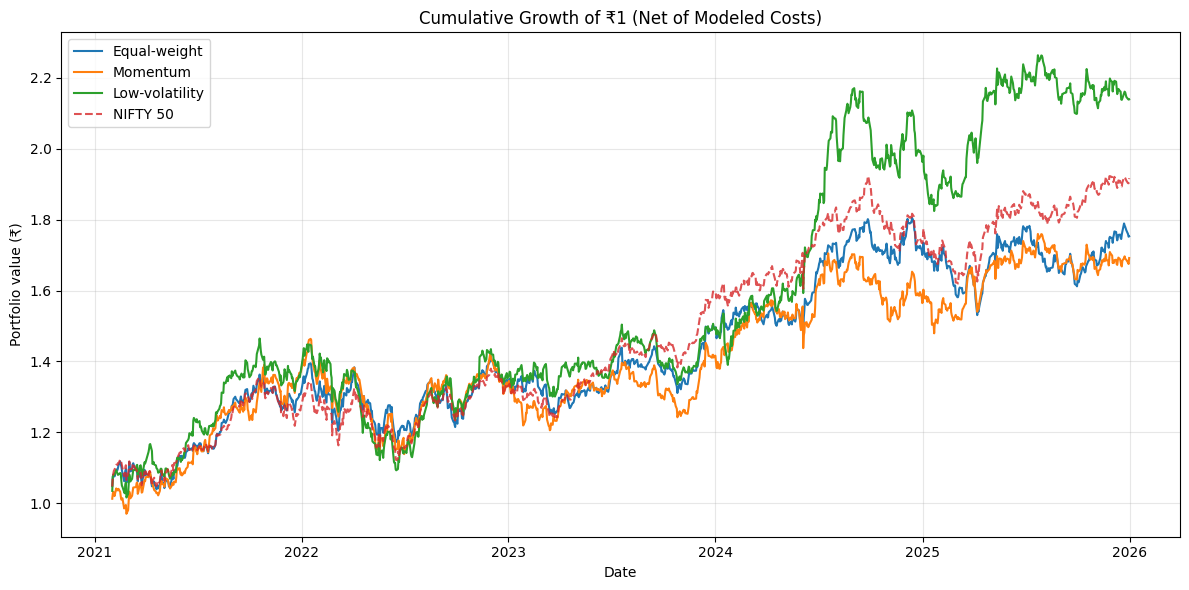

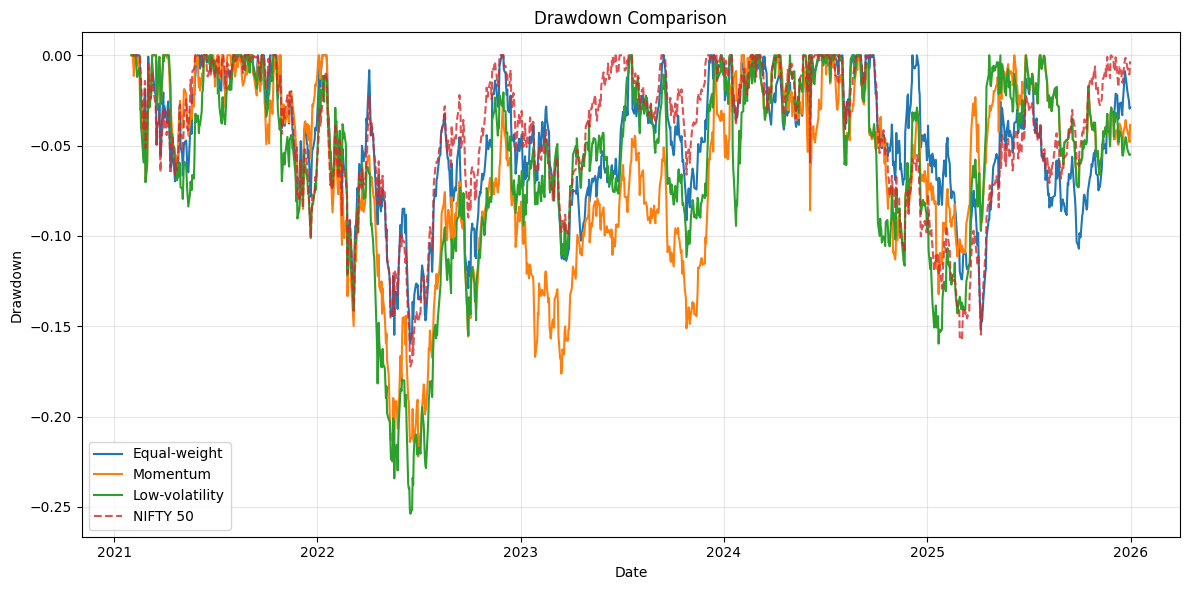

In [18]:
growth = (1 + strategy_returns).cumprod()
if market_common.notna().any():
    market_growth = (1 + market_common.fillna(0)).cumprod()
else:
    market_growth = None

plt.figure(figsize=(12, 6))
for col in growth.columns:
    plt.plot(growth.index, growth[col], label=col)
if market_growth is not None:
    plt.plot(market_growth.index, market_growth, label="NIFTY 50", linestyle="--", alpha=0.8)
plt.title("Cumulative Growth of ₹1 (Net of Modeled Costs)")
plt.ylabel("Portfolio value (₹)")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
for col in growth.columns:
    dd = growth[col] / growth[col].cummax() - 1
    plt.plot(dd.index, dd, label=col)
if market_growth is not None:
    market_dd = market_growth / market_growth.cummax() - 1
    plt.plot(market_dd.index, market_dd, label="NIFTY 50", linestyle="--", alpha=0.8)
plt.title("Drawdown Comparison")
plt.ylabel("Drawdown")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Calendar-year performance

Calendar-year returns reveal whether performance was concentrated in a small number of unusually strong years. The first and last years may be partial years depending on the common evaluation window.

,Equal-weight,Momentum,Low-volatility,NIFTY 50
Year,,,,
2021,31.21%,37.16%,37.52%,27.28%
2022,2.02%,-3.11%,-1.71%,4.33%
2023,11.60%,6.17%,10.48%,20.03%
2024,13.81%,10.87%,31.44%,8.80%
2025,3.10%,8.13%,8.98%,10.51%


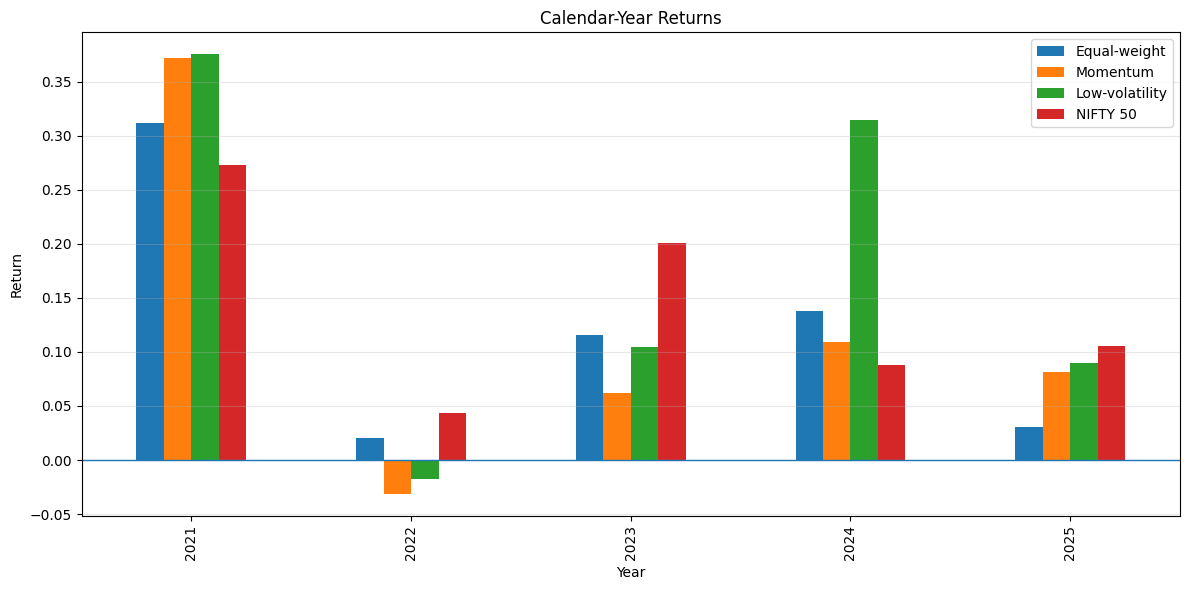

In [19]:
annual_returns = (1 + strategy_returns).groupby(strategy_returns.index.year).prod() - 1
if market_common.notna().any():
    annual_returns["NIFTY 50"] = (1 + market_common).groupby(market_common.index.year).prod() - 1
annual_returns.index.name = "Year"
display(annual_returns.style.format("{:.2%}").set_caption("Calendar-year returns"))

ax = annual_returns.plot(kind="bar", figsize=(12, 6))
ax.set_title("Calendar-Year Returns")
ax.set_ylabel("Return")
ax.set_xlabel("Year")
ax.axhline(0, linewidth=1)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Rolling one-year Sharpe ratio

A rolling Sharpe ratio helps assess stability. It will be undefined until a full rolling window is available. Rolling estimates are noisy and should not be interpreted as precise forecasts.

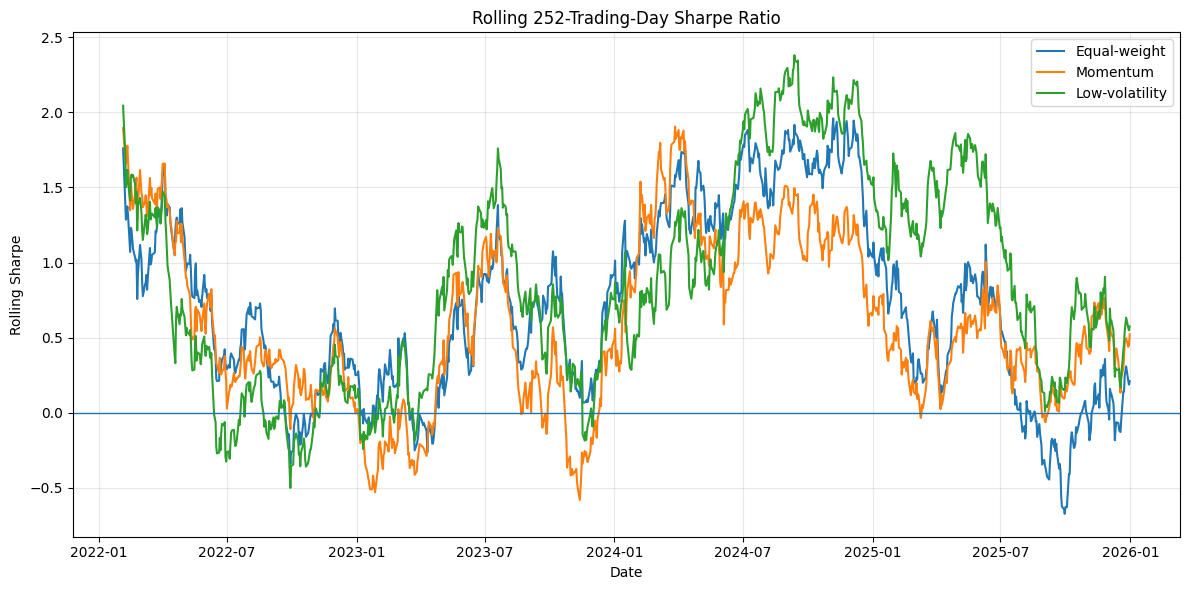

In [20]:
rolling_window = TRADING_DAYS
rolling_sharpe = pd.DataFrame(index=strategy_returns.index)
for col in strategy_returns.columns:
    r = strategy_returns[col]
    mean_excess = r.rolling(rolling_window).mean() - ((1 + RISK_FREE_RATE) ** (1 / TRADING_DAYS) - 1)
    rolling_std = r.rolling(rolling_window).std(ddof=1)
    rolling_sharpe[col] = mean_excess / rolling_std * np.sqrt(TRADING_DAYS)

plt.figure(figsize=(12, 6))
for col in rolling_sharpe.columns:
    plt.plot(rolling_sharpe.index, rolling_sharpe[col], label=col)
plt.axhline(0, linewidth=1)
plt.title("Rolling 252-Trading-Day Sharpe Ratio")
plt.ylabel("Rolling Sharpe")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Benchmark-relative evaluation

For each strategy, calculate annualized active return, tracking error, information ratio, and beta versus the NIFTY 50 reference. These statistics require overlapping valid observations. The five-stock strategy universe and the NIFTY 50 index have different compositions, so relative results should be interpreted cautiously.

In [21]:
relative_rows = []
market_aligned = market_common.rename("NIFTY 50")
for name in strategy_returns.columns:
    pair = pd.concat([strategy_returns[name].rename("strategy"), market_aligned], axis=1).dropna()
    if len(pair) < 2 or pair["NIFTY 50"].var(ddof=1) == 0:
        continue
    active = pair["strategy"] - pair["NIFTY 50"]
    tracking_error = active.std(ddof=1) * np.sqrt(TRADING_DAYS)
    information_ratio = active.mean() / active.std(ddof=1) * np.sqrt(TRADING_DAYS) if active.std(ddof=1) > 0 else np.nan
    beta = pair["strategy"].cov(pair["NIFTY 50"]) / pair["NIFTY 50"].var(ddof=1)
    relative_rows.append({
        "Strategy": name,
        "Annualized Active Return": active.mean() * TRADING_DAYS,
        "Tracking Error": tracking_error,
        "Information Ratio": information_ratio,
        "Beta vs NIFTY 50": beta,
        "Common Observations": len(pair),
    })
relative_metrics = pd.DataFrame(relative_rows).set_index("Strategy")
display(relative_metrics.style.format({
    "Annualized Active Return": "{:.2%}",
    "Tracking Error": "{:.2%}",
    "Information Ratio": "{:.3f}",
    "Beta vs NIFTY 50": "{:.3f}",
}))

,Annualized Active Return,Tracking Error,Information Ratio,Beta vs NIFTY 50,Common Observations
Strategy,,,,,
Equal-weight,-1.65%,6.41%,-0.258,0.998,1216
Momentum,-2.09%,11.36%,-0.184,0.926,1216
Low-volatility,2.85%,11.36%,0.251,0.966,1216


## 11. Transaction-cost sensitivity

Re-run the same strategy targets at several assumed one-way costs. This isolates the impact of the cost assumption while keeping the signal logic fixed. The figures are scenario estimates, not broker quotes.

,Equal-weight,Momentum,Low-volatility
One-way transaction cost (bps),,,
0,75.46%,71.06%,117.32%
5,75.37%,70.11%,115.60%
10,75.29%,69.17%,113.90%
20,75.11%,67.29%,110.54%
30,74.94%,65.44%,107.23%


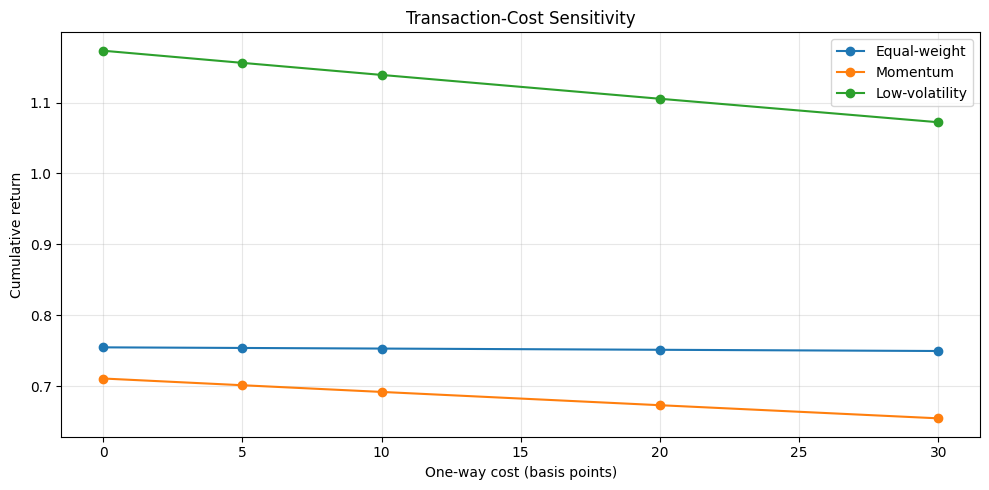

In [22]:
cost_scenarios_bps = [0, 5, 10, 20, 30]
cost_sensitivity = pd.DataFrame(index=cost_scenarios_bps)
for cost_bps in cost_scenarios_bps:
    for name, target in targets.items():
        frame, _ = backtest_strategy(stock_returns, target, cost_bps)
        common_r = frame["Net Return"].loc[strategy_returns.index].dropna()
        m = performance_metrics(common_r, RISK_FREE_RATE)
        cost_sensitivity.loc[cost_bps, name] = m.get("Cumulative Return", np.nan)
cost_sensitivity.index.name = "One-way transaction cost (bps)"
display(cost_sensitivity.style.format("{:.2%}").set_caption("Cumulative return by transaction-cost assumption"))

ax = cost_sensitivity.plot(marker="o", figsize=(10, 5))
ax.set_title("Transaction-Cost Sensitivity")
ax.set_xlabel("One-way cost (basis points)")
ax.set_ylabel("Cumulative return")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Turnover and estimated trading costs

High turnover can erode a strategy's gross advantage. This section summarizes turnover and modeled costs over the common evaluation window.

In [23]:
turnover_summary = []
for name, frame in results.items():
    subset = frame.loc[strategy_returns.index]
    turnover_summary.append({
        "Strategy": name,
        "Cumulative One-way Turnover": subset["Turnover"].sum(),
        "Average Daily Turnover": subset["Turnover"].mean(),
        "Total Modeled Cost (return units)": subset["Transaction Cost"].sum(),
        "Rebalance Days": int((subset["Turnover"] > 0).sum()),
    })
turnover_summary = pd.DataFrame(turnover_summary).set_index("Strategy")
display(turnover_summary.style.format({
    "Cumulative One-way Turnover": "{:.2f}x",
    "Average Daily Turnover": "{:.4f}",
    "Total Modeled Cost (return units)": "{:.4f}",
}))

,Cumulative One-way Turnover,Average Daily Turnover,Total Modeled Cost (return units),Rebalance Days
Strategy,,,,
Equal-weight,0.98x,0.0008,0.0010,59
Momentum,11.15x,0.0092,0.0111,59
Low-volatility,15.92x,0.0131,0.0159,59


## 13. Subperiod robustness check

Compare the first and second halves of the common evaluation period. This is a descriptive check, not a substitute for a properly designed out-of-sample experiment. If you use this split to tune parameters, the later period is no longer an untouched test set.

In [24]:
split_date = strategy_returns.index[len(strategy_returns) // 2]
subperiod_rows = []
for period_name, period_returns in [("First half", strategy_returns.loc[:split_date]), ("Second half", strategy_returns.loc[split_date:])]:
    for name in period_returns.columns:
        m = performance_metrics(period_returns[name], RISK_FREE_RATE)
        subperiod_rows.append({
            "Period": period_name,
            "Strategy": name,
            "Cumulative Return": m.get("Cumulative Return", np.nan),
            "CAGR": m.get("CAGR", np.nan),
            "Volatility": m.get("Annualized Volatility", np.nan),
            "Sharpe": m.get("Sharpe Ratio", np.nan),
            "Max Drawdown": m.get("Maximum Drawdown", np.nan),
        })
subperiod_table = pd.DataFrame(subperiod_rows).set_index(["Period", "Strategy"])
display(subperiod_table.style.format({
    "Cumulative Return": "{:.2%}", "CAGR": "{:.2%}", "Volatility": "{:.2%}",
    "Sharpe": "{:.3f}", "Max Drawdown": "{:.2%}"
}))

## 14. Interpretation checklist

Use the outputs above to answer these questions in your own words:

1. Which strategy has the highest CAGR, and does it also have the highest Sharpe ratio?
2. Which strategy experiences the deepest drawdown?
3. Does any strategy outperform NIFTY 50 on both absolute and risk-adjusted terms?
4. How much do rankings change as transaction costs rise?
5. Are results consistent across the first and second halves of the sample?
6. What additional evidence would you need before trusting the result?

Avoid choosing a strategy solely because it wins on one metric. Consider return, drawdown, turnover, benchmark-relative performance, and stability together.

## 15. Limitations and next steps

### Limitations
- The strategy universe contains only five large Indian stocks. It is not representative of the full investable market.
- The analysis uses currently available historical constituents and does not correct for survivorship bias.
- Historical estimates of momentum and volatility can be unstable, and parameter choices may be data-mined.
- Transaction costs are simplified and do not include taxes, spread variation, market impact, liquidity constraints, or actual fill prices.
- The NIFTY 50 comparison is a reference comparison, not a perfectly matched investable benchmark in this implementation.
- No guarantee exists that historical factor performance will persist.

### Suggested next steps
1. Expand the universe and document stock-selection rules before testing.
2. Use a point-in-time universe where possible to reduce survivorship bias.
3. Evaluate alternative lookback windows only within a disciplined train/validation/test design.
4. Add realistic costs and liquidity constraints.
5. Preserve this notebook's parameters and results before experimenting with new variants.

## Conclusion

This notebook provides a consistent framework for evaluating factor strategies using returns, drawdowns, rolling risk-adjusted performance, benchmark-relative statistics, turnover, and cost sensitivity. The strongest conclusion is not simply which strategy won, but whether the result remains credible across metrics, periods, and reasonable cost assumptions.